In [21]:
import warnings

import matplotlib.pyplot as plt

from utils.results import (formulations_in, load_results, select,
                           simplify_labels, summary_table, order_formulations)
from utils.plots import (coverage_heatmap, pairwise_scatter,
                         performance_profile, scaling_plot)

warnings.simplefilter('always', UserWarning)
plt.rcParams['figure.dpi'] = 110

# SOURCE = 'aws-B-S.xlsx'
SOURCE = 'aws.csv'
df = load_results(SOURCE)

df = df[df['n'] != 10]

# PBF decomposed with enumerative cuts is dominated by the dual cut. Dropping
# it from the frame rather than from each call keeps it out of every figure
# and table, and keeps the colour ramps as coarse as the kept set needs.
df = select(df, labels_only=False,
            exclude=dict(base='PBF', extended=False,
                         decomposition=True, cut='enum'))
ALL = formulations_in(df)

# Performance profiles carry exact formulations only. A monolithic
# approximation (-A without -D) reports a bound that is not valid for the
# CETSP, so putting it on the same axis is not a like-for-like comparison.

PROFILE= select(df, formulations=ALL, base=['ABF', 'SBF', 'PBF'],
                 exclude=dict(extended=True))

LABELS = None          # None = -S/-OC/-B dropped, cut names kept only where
                       # they separate two variants of the same decomposition
TIME_SCALE = 'linear'

list(zip(PROFILE, simplify_labels(PROFILE)))

[('ABF-S-B', 'ABF'),
 ('ABF-D-S-B', 'ABF-D'),
 ('SBF-B', 'SBF'),
 ('SBF-D-dual-B', 'SBF-D'),
 ('PBF-S-B', 'PBF'),
 ('PBF-D-dual-S-OC-B', 'PBF-D')]

In [22]:
from utils.results import load_results, failed_runs
failed_runs(load_results('aws.csv'))

,Kind,Formulation,n,r_min,r_max,Instance,Status,Time
0,recorded failure,SBF-B,20,0.400,0.600,3,Crashed,1800.0
1,recorded failure,SBF-B,25,0.125,0.375,0,Crashed,1800.0
2,recorded failure,SBF-B,25,0.125,0.375,4,Crashed,1800.0


C:\Users\daray\AppData\Local\Temp\ipykernel_27948\753128527.py:1: UserWarning: uneven coverage over 180 instance cells: SBF-B missing 3.  Curves and means are over different instance sets; pass align=True to restrict to the common cells.
  performance_profile(df, PROFILE, labels=LABELS, time_scale=TIME_SCALE,


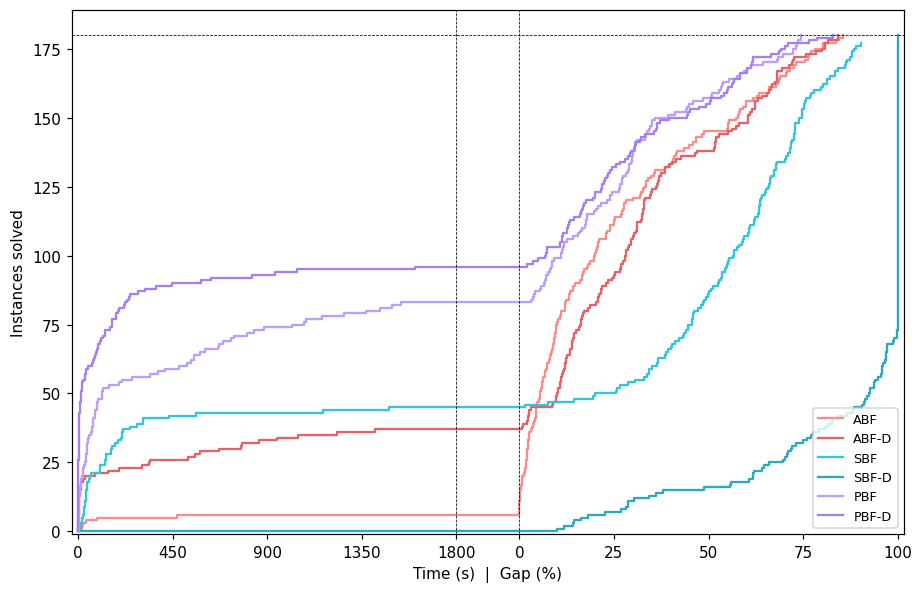

In [23]:
performance_profile(df, PROFILE, labels=LABELS, time_scale=TIME_SCALE,
                    title=None,
                    figsize=(8.5, 5.5), filename='performance_profile_1.png')

In [48]:
table = summary_table(df, PROFILE, labels=LABELS, metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Nodes'))
print(table.to_latex(index=False))

\begin{tabular}{llllll}
\toprule
Formulation & Opt & TimeOpt & Gap (%) & Gap NoOpt (%) & Nodes \\
\midrule
ABF-S-B & 6 & 106.95 & 24.91 & 25.77 & 197738 \\
ABF-D-S-B & 37 & 296.01 & 27.82 & 35.01 & 336128 \\
SBF-B & 45 & 178.05 & 43.78 & 58.71 & 484881 \\
SBF-D-dual-B & 0 & - & 88.29 & 88.29 & 238701 \\
PBF-S-B & 83 & 306.38 & 17.19 & 31.89 & 43710 \\
PBF-D-dual-S-OC-B & 96 & 118.02 & 16.12 & 34.54 & 360391 \\
\bottomrule
\end{tabular}



C:\Users\daray\AppData\Local\Temp\ipykernel_27948\368663843.py:1: UserWarning: uneven coverage over 180 instance cells: SBF-B missing 3.  Curves and means are over different instance sets; pass align=True to restrict to the common cells.
  table = summary_table(df, PROFILE, labels=LABELS, metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Nodes'))


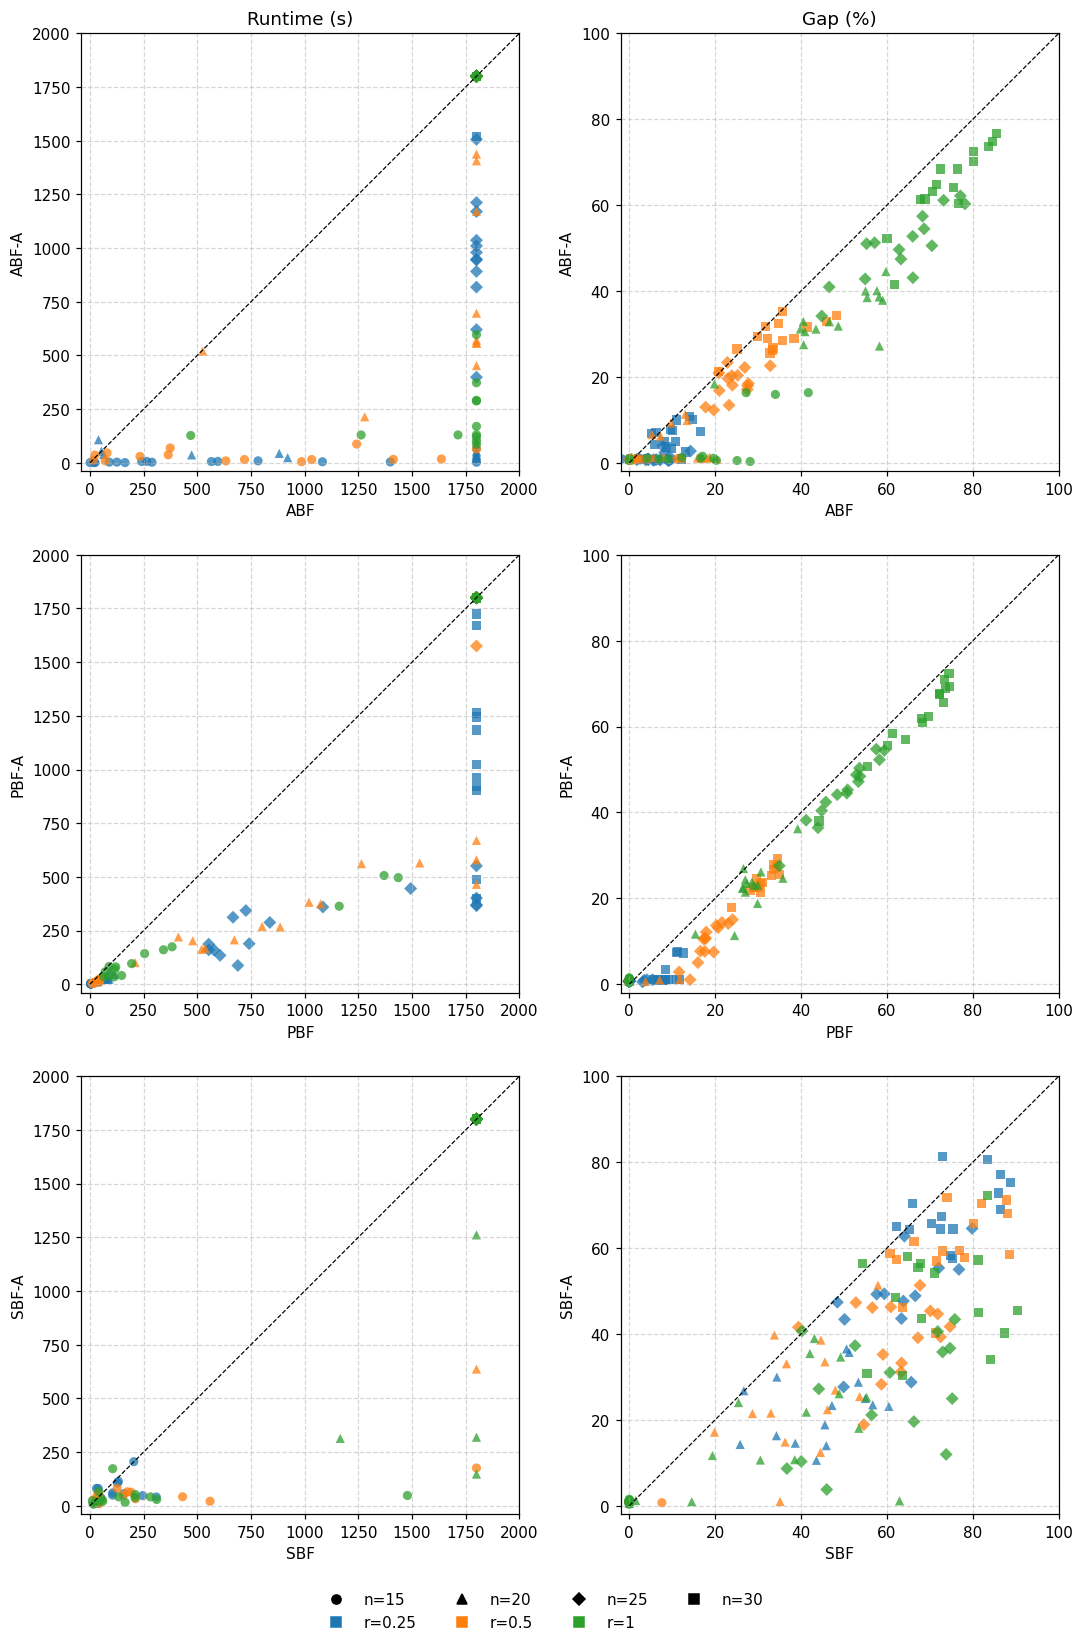

In [25]:
PAIRS = [(select(df, base=b, extended=False, decomposition=False)[0],
          select(df, base=b, extended=True,  decomposition=False)[0])
         for b in ('ABF', 'PBF', 'SBF')]

pairwise_scatter(df, pairs=PAIRS, metrics=('Time', 'GapPct'),
                 color_by='r_mean', marker_by='n',
                 figsize=None, filename='pairwise_scatter_1.png')

In [26]:
MONO_VS_APPROX = select(df, base=['ABF', 'PBF', 'SBF'], decomposition = False)
MONO_VS_APPROX

['ABF-S-B', 'ABF-A-S-B', 'SBF-B', 'SBF-A-B', 'PBF-S-B', 'PBF-A-S-B']

In [49]:
table = summary_table(df, MONO_VS_APPROX, labels=simplify_labels(MONO_VS_APPROX), metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Nodes'))
print(table.to_latex(index=False))

\begin{tabular}{llllll}
\toprule
Formulation & Opt & TimeOpt & Gap (%) & Gap NoOpt (%) & Nodes \\
\midrule
ABF & 6 & 106.95 & 24.91 & 25.77 & 197738 \\
ABF-A & 80 & 306.10 & 17.86 & 31.44 & 276901 \\
SBF & 45 & 178.05 & 43.78 & 58.71 & 484881 \\
SBF-A & 50 & 99.31 & 29.88 & 41.03 & 1477916 \\
PBF & 83 & 306.38 & 17.19 & 31.89 & 43710 \\
PBF-A & 102 & 254.23 & 14.28 & 31.74 & 21459 \\
\bottomrule
\end{tabular}



C:\Users\daray\AppData\Local\Temp\ipykernel_27948\2902821472.py:1: UserWarning: uneven coverage over 180 instance cells: SBF-B missing 3.  Curves and means are over different instance sets; pass align=True to restrict to the common cells.
  table = summary_table(df, MONO_VS_APPROX, labels=simplify_labels(MONO_VS_APPROX), metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Nodes'))


In [28]:
approx = {"ABF-A": "ABF-A-S-B", "PBF-A": "PBF-A-S-B", "SBF-A": "SBF-A-B"}

sub = df[df["Formulation"].isin(approx.values()) & (df["n"] >= 15)].copy()
sub["Name"] = sub["Formulation"].map({v: k for k, v in approx.items()})
sub["r"] = (sub["r_min"] + sub["r_max"]) / 2
sub["Gap (%)"] = 100 * sub["Gap"]

opt = sub[sub["Status"] == "Optimal"]

print("Gap (%) on instances where the approximation is solved to optimality")
display(opt.groupby("Name")["Gap (%)"].describe()[["count", "mean", "50%", "max"]].round(3))

print("Mean gap (%) by n and r")
display(opt.pivot_table(index="Name", columns=["n", "r"], values="Gap (%)", aggfunc="mean").round(3))

Gap (%) on instances where the approximation is solved to optimality


,count,mean,50%,max
Name,,,,
ABF-A,80.0,0.891,0.880,1.529
PBF-A,102.0,0.935,0.932,1.529
SBF-A,50.0,0.913,0.944,1.529


Mean gap (%) by n and r


n         15                   20                   25           30
r       0.25   0.50   1.00   0.25   0.50   1.00   0.25  0.50   0.25
Name                                                               
ABF-A  0.879  0.830  0.886  0.930  1.157    NaN  0.714   NaN  0.885
PBF-A  0.919  0.886  0.906  0.968  1.092    NaN  0.768  1.06  1.018
SBF-A  0.920  0.882  0.918    NaN  1.001  0.965    NaN   NaN    NaN

In [29]:
D_VS_D_A = select(df, base=['ABF', 'PBF', 'SBF'], decomposition=True)


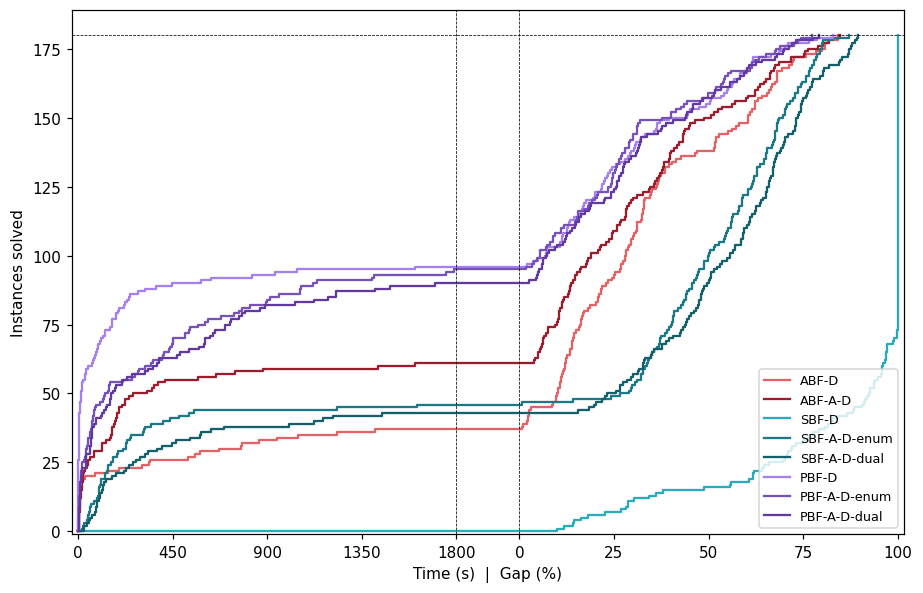

In [30]:
performance_profile(df, D_VS_D_A, labels=simplify_labels(D_VS_D_A), time_scale=TIME_SCALE,
                    title=None,
                    figsize=(8.5, 5.5), filename='performance_profile_2.png')

In [50]:
table = summary_table(df, D_VS_D_A, labels=simplify_labels(D_VS_D_A), metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Cuts', 'Nodes'))
print(table.to_latex(index=False))

\begin{tabular}{lllllll}
\toprule
Formulation & Opt & TimeOpt & Gap (%) & Gap NoOpt (%) & Cuts & Nodes \\
\midrule
ABF-D & 37 & 296.01 & 27.82 & 35.01 & 41630.68 & 336128 \\
ABF-A-D & 61 & 198.33 & 22.87 & 34.59 & 137.28 & 277307 \\
SBF-D & 0 & - & 88.29 & 88.29 & 5231.48 & 238701 \\
SBF-A-D-enum & 46 & 235.01 & 40.93 & 54.98 & 543.13 & 1301516 \\
SBF-A-D-dual & 43 & 344.51 & 43.90 & 57.68 & 427.53 & 776271 \\
PBF-D & 96 & 118.02 & 16.12 & 34.54 & 1463.11 & 360391 \\
PBF-A-D-enum & 95 & 330.53 & 15.44 & 32.70 & 172.41 & 19123 \\
PBF-A-D-dual & 90 & 324.73 & 16.77 & 33.55 & 117.04 & 17484 \\
\bottomrule
\end{tabular}



In [32]:
RADII_SELECTION = order_formulations(
    select(df, base='ABF', extended=True,  decomposition=True)
  + select(df, base='SBF', extended=True,  decomposition=True, cut='enum')
  + select(df, base='PBF', extended=False, decomposition=True, cut='dual')
  + select(df, base='PBF', extended=True,  decomposition=True, cut='enum'))

RADII_SELECTION

['ABF-A-D-S-B', 'SBF-A-D-enum-B', 'PBF-D-dual-S-OC-B', 'PBF-A-D-enum-S-B']

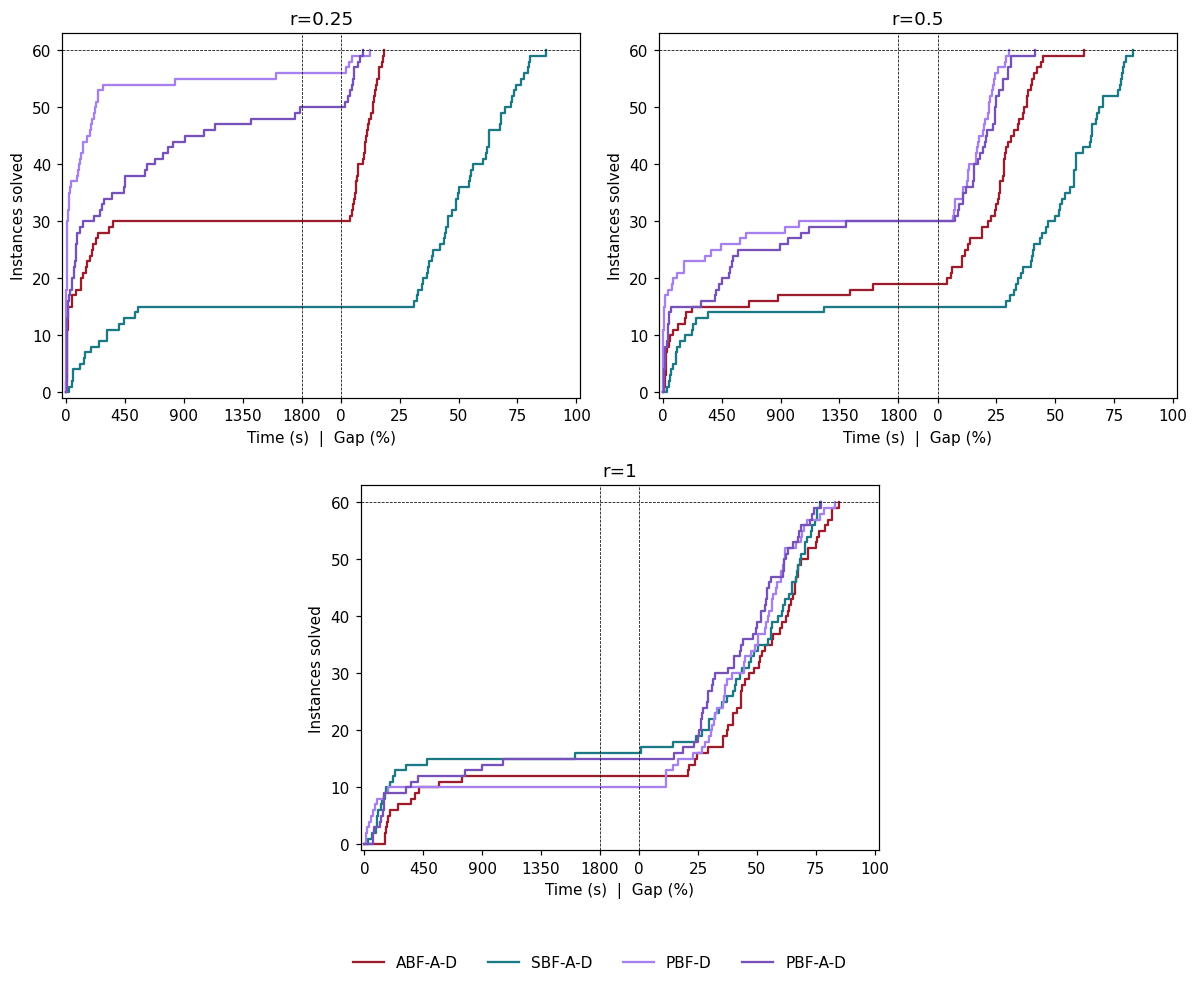

In [33]:
performance_profile(df, RADII_SELECTION, labels=simplify_labels(RADII_SELECTION), facet_by='r_mean',
                    time_scale='linear', filename='performance_profile_3.png', ncols = 2)

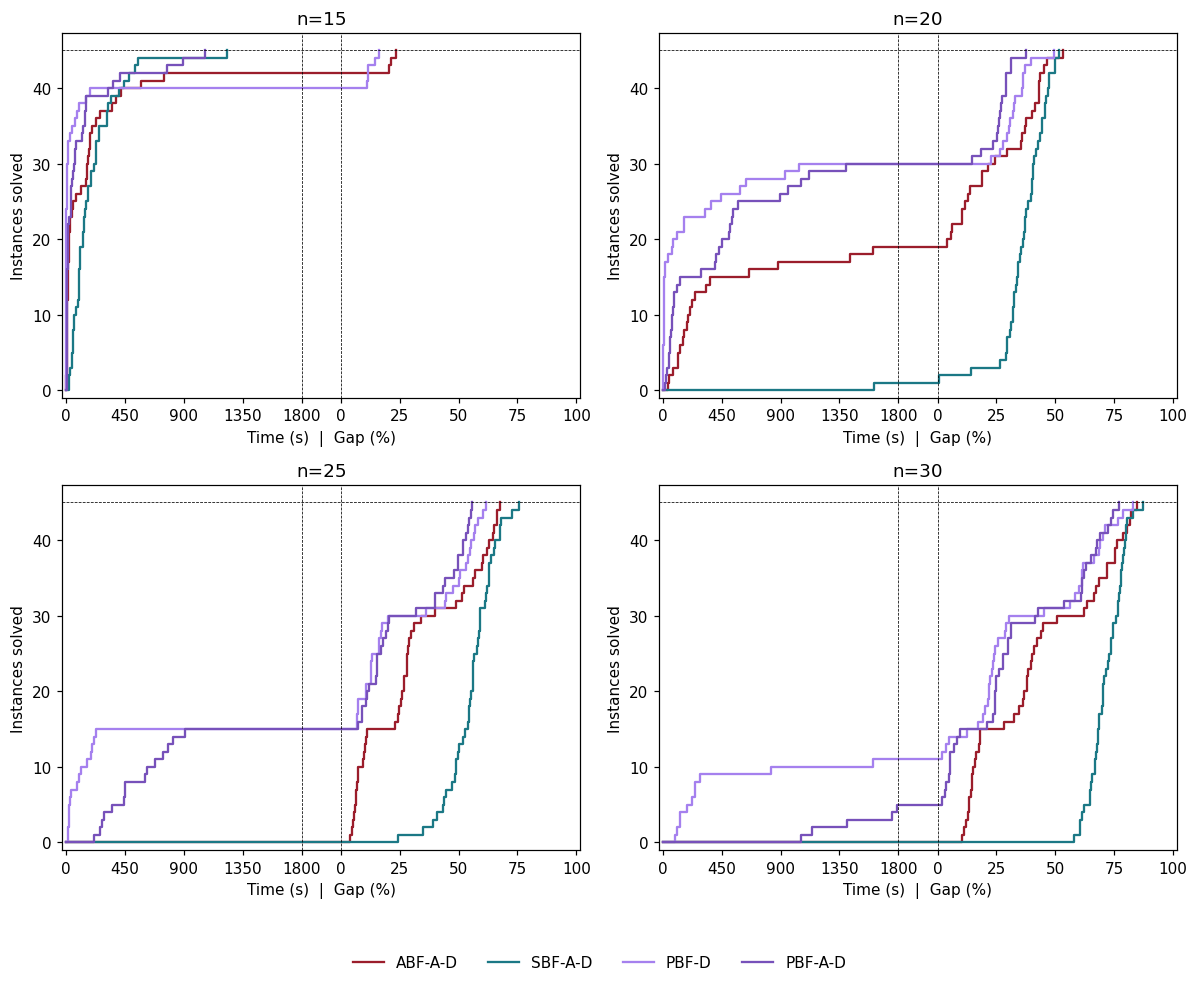

In [34]:
performance_profile(df, RADII_SELECTION, labels=simplify_labels(RADII_SELECTION), facet_by='n',
                    time_scale='linear', filename='performance_profile_4.png')

In [35]:
pbfd = df[(df["Formulation"] == "PBF-D-dual-S-OC-B") & (df["n"] >= 15)].copy()
pbfd["r"] = (pbfd["r_min"] + pbfd["r_max"]) / 2

opt_r1 = pbfd[(pbfd["r"] == 1) & (pbfd["Status"] == "Optimal")]
display(opt_r1.groupby("n").agg(Opt=("Time", "size"), MeanTime=("Time", "mean")).round(2))

,Opt,MeanTime
n,,
15,10,69.62


In [51]:
table = summary_table(df, RADII_SELECTION, labels=simplify_labels(RADII_SELECTION), by='r_mean', metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Cuts', 'Nodes')).rename(columns={'r_mean': 'r'})
print(table.to_latex(index=False))

\begin{tabular}{lrllllll}
\toprule
Formulation & r & Opt & TimeOpt & Gap (%) & Gap NoOpt (%) & Cuts & Nodes \\
\midrule
ABF-A-D & 0.250000 & 30 & 90.65 & 5.50 & 11.01 & 84.50 & 143358 \\
ABF-A-D & 0.500000 & 19 & 295.52 & 19.08 & 27.93 & 102.95 & 277988 \\
ABF-A-D & 1.000000 & 12 & 313.65 & 44.02 & 55.03 & 224.38 & 410576 \\
SBF-A-D & 0.250000 & 15 & 236.14 & 41.77 & 55.69 & 355.23 & 1358840 \\
SBF-A-D & 0.500000 & 15 & 210.62 & 42.30 & 56.40 & 424.63 & 1256492 \\
SBF-A-D & 1.000000 & 16 & 256.81 & 38.71 & 52.79 & 849.52 & 1289217 \\
PBF-D & 0.250000 & 56 & 99.96 & 0.38 & 5.75 & 376.70 & 100898 \\
PBF-D & 0.500000 & 30 & 167.85 & 9.02 & 18.03 & 1101.15 & 414247 \\
PBF-D & 1.000000 & 10 & 69.62 & 38.95 & 46.74 & 2911.47 & 566027 \\
PBF-A-D & 0.250000 & 50 & 321.79 & 0.91 & 5.43 & 106.25 & 7992 \\
PBF-A-D & 0.500000 & 30 & 348.66 & 10.46 & 20.91 & 135.78 & 16133 \\
PBF-A-D & 1.000000 & 15 & 323.39 & 34.97 & 46.62 & 275.18 & 33244 \\
\bottomrule
\end{tabular}



In [52]:
table = summary_table(df, RADII_SELECTION, labels=simplify_labels(RADII_SELECTION), by='n', metrics=('Opt', 'TimeOpt', 'Gap (%)', 'Gap NoOpt (%)', 'Cuts', 'Nodes')).rename(columns={'r_mean': 'r'})
print(table.to_latex(index=False))

\begin{tabular}{lrllllll}
\toprule
Formulation & n & Opt & TimeOpt & Gap (%) & Gap NoOpt (%) & Cuts & Nodes \\
\midrule
ABF-A-D & 15 & 42 & 117.59 & 1.45 & 21.82 & 171.93 & 203143 \\
ABF-A-D & 20 & 19 & 376.80 & 16.32 & 28.24 & 137.13 & 417329 \\
ABF-A-D & 25 & 0 & - & 31.28 & 31.28 & 128.93 & 306096 \\
ABF-A-D & 30 & 0 & - & 42.43 & 42.43 & 111.11 & 182660 \\
SBF-A-D & 15 & 45 & 204.39 & 0.00 & - & 946.16 & 444759 \\
SBF-A-D & 20 & 1 & 1612.95 & 36.43 & 37.26 & 690.96 & 2195628 \\
SBF-A-D & 25 & 0 & - & 55.44 & 55.44 & 275.29 & 1534943 \\
SBF-A-D & 30 & 0 & - & 71.84 & 71.84 & 260.11 & 1030735 \\
PBF-D & 15 & 40 & 18.64 & 1.44 & 12.99 & 800.58 & 72979 \\
PBF-D & 20 & 30 & 168.66 & 11.10 & 33.31 & 1470.93 & 340889 \\
PBF-D & 25 & 15 & 97.20 & 21.62 & 32.42 & 1984.71 & 470155 \\
PBF-D & 30 & 11 & 369.65 & 30.30 & 40.11 & 1596.20 & 557539 \\
PBF-A-D & 15 & 45 & 119.00 & 0.00 & - & 166.56 & 16321 \\
PBF-A-D & 20 & 30 & 367.45 & 8.91 & 26.73 & 154.11 & 29718 \\
PBF-A-D & 25 & 15 & 525.12 &

In [38]:
BS_VS_PBF_D = order_formulations(
    select(df, base='BS') +
    select(df, base='PBF', extended=False, decomposition=True, cut='dual'))
BS_VS_PBF_D

['PBF-D-dual-S-OC-B', 'BS-B']

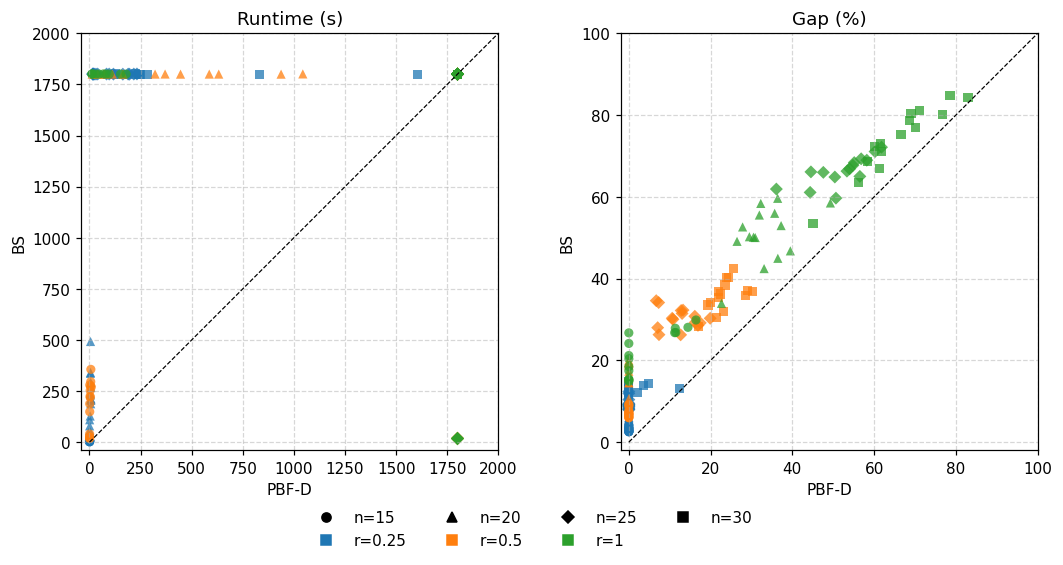

In [39]:
X, Y = BS_VS_PBF_D[0], BS_VS_PBF_D[1]
pairwise_scatter(df, X, Y, metrics=('Time', 'GapPct'),
                 color_by='r_mean', marker_by='n', filename='pairwise_scatter_2.png',
                 title='')

In [40]:
from utils.results import head_to_head, summary_table

BS  = next(f for f in BS_VS_PBF_D if f.startswith('BS'))
PBF = next(f for f in BS_VS_PBF_D if f.startswith('PBF'))

# --- paired -----------------------------------------------------------------
paired = head_to_head(df, BS, PBF, by='n', time='completed')
paired = paired[['n', 'Cells', 'BS solved', 'PBF-D solved',
                 'Both', 'Only PBF-D', 'Neither',
                 'PBF-D faster', 'PBF-D tighter',
                 'Time BS', 'Time PBF-D', 'Gap BS', 'Gap PBF-D']]
paired.columns = ['$n$', 'inst.', 'BS', 'PBF-D', 'both', 'PBF-D only',
                  'neither', 'PBF-D faster', 'PBF-D tighter',
                  'time BS (s)', 'time PBF-D (s)',
                  'gap BS (\\%)', 'gap PBF-D (\\%)']

print(paired.to_latex(index=False, float_format='%.2f', na_rep='--',
                      escape=False,
                      caption='B\\&S against PBF-D, paired by instance. '
                              '\\emph{solved} counts runs terminating '
                              '\\texttt{Optimal}; for B\\&S this means its '
                              'refinement schedule finished, which leaves a '
                              'discretisation gap open. Times are means over '
                              'each method\'s own completed runs, so the two '
                              'columns average different instance sets and '
                              'are not directly comparable; a dash marks a '
                              'size where nothing completed.',
                      label='tab:bs-pbf-paired', position='tb'))

# --- aggregate --------------------------------------------------------------
agg = summary_table(df, [BS, PBF], by='n',
                    metrics=('Runs', 'Opt', 'TimeOpt', 'Gap (%)',
                             'RootGap (%)'))
agg.columns = ['formulation', '$n$', 'runs', 'opt.', 'time (s)',
               'gap (\\%)', 'root gap (\\%)']

print(agg.to_latex(index=False, escape=False,
                   caption='B\\&S against PBF-D, aggregate by instance size. '
                           'Time is the mean over completed runs.',
                   label='tab:bs-pbf-aggregate', position='tb'))

\begin{table}[tb]
\caption{B\&S against PBF-D, paired by instance. \emph{solved} counts runs terminating \texttt{Optimal}; for B\&S this means its refinement schedule finished, which leaves a discretisation gap open. Times are means over each method's own completed runs, so the two columns average different instance sets and are not directly comparable; a dash marks a size where nothing completed.}
\label{tab:bs-pbf-paired}
\begin{tabular}{rrrrrrrrrrrrr}
\toprule
$n$ & inst. & BS & PBF-D & both & PBF-D only & neither & PBF-D faster & PBF-D tighter & time BS (s) & time PBF-D (s) & gap BS (\%) & gap PBF-D (\%) \\
\midrule
15 & 45 & 30 & 40 & 30 & 10 & 5 & 30 & 5 & 90.86 & 18.64 & 10.75 & 1.44 \\
20 & 45 & 15 & 30 & 15 & 15 & 15 & 15 & 15 & 225.80 & 168.66 & 24.10 & 11.10 \\
25 & 45 & 0 & 15 & 0 & 15 & 30 & 0 & 30 & -- & 97.20 & 35.31 & 21.62 \\
30 & 45 & 0 & 11 & 0 & 11 & 34 & 0 & 34 & -- & 369.65 & 41.00 & 30.30 \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}[tb]
\caption{B\&S a

In [41]:
from utils.results import head_to_head

BS  = next(f for f in BS_VS_PBF_D if f.startswith('BS'))
PBF = next(f for f in BS_VS_PBF_D if f.startswith('PBF'))

t = head_to_head(df, BS, PBF, by='n')[
        ['n', 'BS solved', 'SGM BS', 'Gap BS',
         'PBF-D solved', 'SGM PBF-D', 'Gap PBF-D']]
t.columns = ['$n$', 'BS completed', 'BS time (SGM)', 'BS gap (\\%)',
             'PBF-D optimal', 'PBF-D time (SGM)', 'PBF-D gap (\\%)']

display(t)
print(t.to_latex(index=False, float_format='%.2f', escape=False,
                 caption='B\\&S against PBF-D, 9 instances per size. '
                         '\\emph{completed} counts B\\&S runs that finished '
                         'their refinement schedule, which leaves a '
                         'discretisation gap open and is not a proof of '
                         'optimality; \\emph{optimal} counts PBF-D runs that '
                         'closed. SGM is the shifted geometric mean runtime '
                         'in seconds over all runs (shift 10), timeouts '
                         'included at the limit.',
                 label='tab:bs-pbf', position='tb'))

,$n$,BS completed,BS time (SGM),BS gap (\%),PBF-D optimal,PBF-D time (SGM),PBF-D gap (\%)
0,15,30,145.077958,10.748969,40,19.133169,1.443671
1,20,15,871.245980,24.103348,30,161.165755,11.104389
2,25,0,1129.450636,35.306034,15,621.171106,21.615263
3,30,0,1800.242991,40.998397,11,1107.852201,30.302860


\begin{table}[tb]
\caption{B\&S against PBF-D, 9 instances per size. \emph{completed} counts B\&S runs that finished their refinement schedule, which leaves a discretisation gap open and is not a proof of optimality; \emph{optimal} counts PBF-D runs that closed. SGM is the shifted geometric mean runtime in seconds over all runs (shift 10), timeouts included at the limit.}
\label{tab:bs-pbf}
\begin{tabular}{rrrrrrr}
\toprule
$n$ & BS completed & BS time (SGM) & BS gap (\%) & PBF-D optimal & PBF-D time (SGM) & PBF-D gap (\%) \\
\midrule
15 & 30 & 145.08 & 10.75 & 40 & 19.13 & 1.44 \\
20 & 15 & 871.25 & 24.10 & 30 & 161.17 & 11.10 \\
25 & 0 & 1129.45 & 35.31 & 15 & 621.17 & 21.62 \\
30 & 0 & 1800.24 & 41.00 & 11 & 1107.85 & 30.30 \\
\bottomrule
\end{tabular}
\end{table}



In [42]:
from utils.results import pairwise_table
# --- Point 2: PBF-D's gap is never worse ------------------------------------
p = pairwise_table(df, BS, PBF, metrics=('Time', 'GapPct', 'Status'))
not_worse = p.GapPct_y <= p.GapPct_x + 1e-12
print(f'PBF-D gap <= BS gap on {not_worse.sum()} of {len(p)} instances')
print(p.assign(w=not_worse).groupby('n').w.agg(['sum', 'count']))

PBF-D gap <= BS gap on 180 of 180 instances
    sum  count
n             
15   45     45
20   45     45
25   45     45
30   45     45


In [43]:
# --- Point 3: BS gap among runs that terminated without the time limit ------
done = df[(df.Formulation == BS) & (df.Status == 'Optimal')]
print(done.groupby('n').GapPct.agg(['count', 'mean', 'max', 'min']))
print(f'overall: {len(done)} runs, mean {done.GapPct.mean():.2f}%, '
      f'max {done.GapPct.max():.2f}%, min {done.GapPct.min():.2f}%')

    count      mean       max       min
n                                      
15     30  5.172302  9.197607  2.531864
20     15  4.631904  6.054103  3.458033
overall: 45 runs, mean 4.99%, max 9.20%, min 2.53%


In [44]:
p = pairwise_table(df, BS, PBF, metrics=('Time', 'GapPct', 'UB', 'LB', 'Status'))
known = p[p.Status_y == 'Optimal']
print(known.GapPct_x.max())      # 26.73
print(known.GapPct_x.mean())     # 8.50

26.732592986800903
9.894429368900026


In [45]:
summary_table(df, ALL, labels=PROFILE, by='n',
              metrics=('Runs', 'Opt', 'TimeOpt', 'Gap (%)', 'RootGap (%)'))

C:\Users\daray\AppData\Local\Temp\ipykernel_27948\1193072190.py:1: UserWarning: uneven coverage over 180 instance cells: SBF-B missing 3.  Curves and means are over different instance sets; pass align=True to restrict to the common cells.
  summary_table(df, ALL, labels=PROFILE, by='n',


,Formulation,n,Runs,Opt,TimeOpt,Gap (%),RootGap (%)
0,ABF-S-B,15,45,5,120.36,7.58,42.17
1,ABF-S-B,20,45,1,39.92,20.63,50.80
2,ABF-S-B,25,45,0,-,31.63,56.22
3,ABF-S-B,30,45,0,-,39.80,60.38
4,ABF-D-S-B,15,45,26,165.84,9.91,31.92
5,ABF-D-S-B,20,45,11,603.67,24.64,36.98
6,ABF-D-S-B,25,45,0,-,35.20,41.15
7,ABF-D-S-B,30,45,0,-,41.51,45.96
8,SBF-B,15,45,42,73.30,1.89,41.66
9,SBF-B,20,45,25,334.25,12.70,49.83


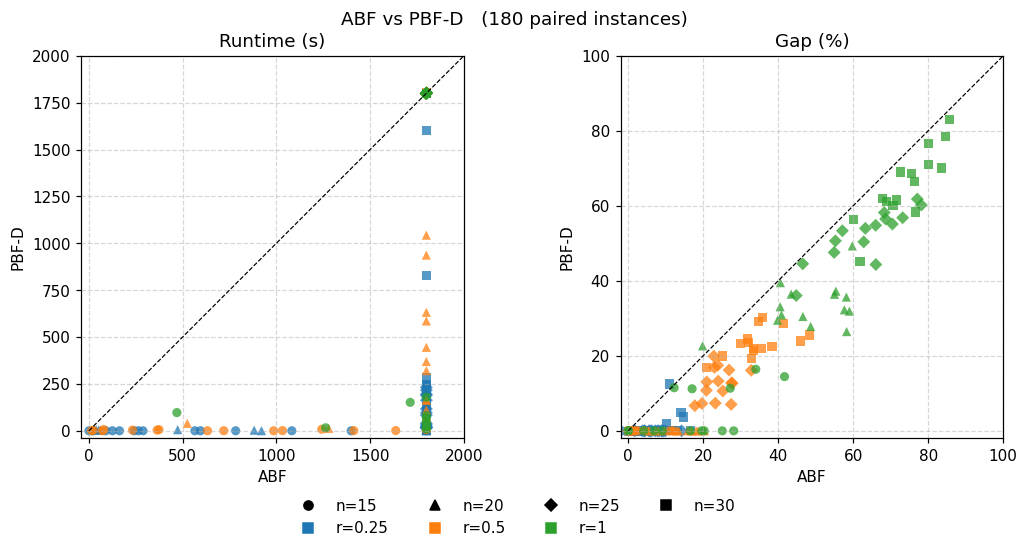

In [46]:
pairwise_scatter(df, PROFILE[0], PROFILE[-1],
                 metrics=('Time', 'GapPct'), color_by='r_mean', marker_by='n')

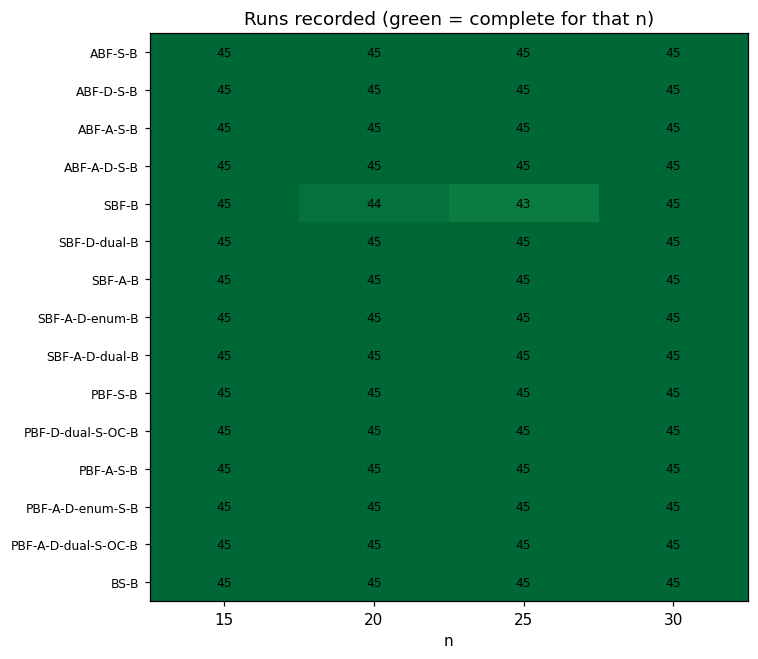

In [47]:
coverage_heatmap(df, ALL, over='n')